# Logistic Regression — Titanic Mini Capstone

**Phạm vi:** Thành viên 1 — Logistic Regression. Notebook chỉ đọc dữ liệu từ `artifacts/common/` (data contract do notebook chung `00_common_pipeline.ipynb` tạo ra).

**Các bước chung đã hoàn thành (không thực hiện lại ở đây):** audit dữ liệu thô, EDA, impute theo thống kê của train (Embarked mode, Fare median, Age median theo Sex×Pclass), feature engineering (Title, FamilySize, FamilyCategory, AgeBand, FareBand), one-hot encoding, hold-out split chung (`test_size=0.2`, stratify, `random_state=42`) và hợp đồng CV 10-fold.

**Nguyên tắc:** scaler chỉ nằm trong `Pipeline` nên chỉ được fit trên training fold; validation và test Kaggle không tham gia fit/tuning.

## 1. Setup

In [1]:
from pathlib import Path
import json, time, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'PROJECT_PLAN.md').exists())
COMMON_DIR = ROOT / 'artifacts' / 'common'
OUT_DIR = ROOT / 'artifacts' / 'logistic_regression'
FIG_DIR = ROOT / 'reports' / 'figures' / 'logistic_regression'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_STATE)
pd.set_option('display.width', 160)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| sklearn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | numpy 2.5.4 | pandas 3.1.0 | sklearn 1.9.1 | matplotlib 3.11.2


## 2. Đọc shared artifacts và kiểm tra schema theo manifest

In [2]:
manifest = json.loads((COMMON_DIR / 'feature_manifest.json').read_text(encoding='utf-8'))
FEATURES, TARGET = manifest['features'], manifest['target']

X_train = pd.read_csv(COMMON_DIR / 'X_train.csv')
X_valid = pd.read_csv(COMMON_DIR / 'X_valid.csv')
y_train = pd.read_csv(COMMON_DIR / 'y_train.csv')[TARGET]
y_valid = pd.read_csv(COMMON_DIR / 'y_valid.csv')[TARGET]
X_full = pd.read_csv(COMMON_DIR / 'X_full.csv')
y_full = pd.read_csv(COMMON_DIR / 'y_full.csv')[TARGET]
X_test = pd.read_csv(COMMON_DIR / 'X_test.csv')
test_passenger_id = pd.read_csv(COMMON_DIR / 'test_passenger_id.csv')['PassengerId']

# Hợp đồng dữ liệu
assert manifest['random_state'] == RANDOM_STATE
assert manifest['cv'] == {'method': 'StratifiedKFold', 'n_splits': 10, 'shuffle': True, 'random_state': 42,
                          'primary_metric': 'accuracy', 'additional_metrics': ['precision', 'recall', 'f1', 'roc_auc', 'confusion_matrix']}
for name, X in {'X_train': X_train, 'X_valid': X_valid, 'X_full': X_full, 'X_test': X_test}.items():
    assert X.columns.tolist() == FEATURES, f'{name}: sai tên/thứ tự feature'
    assert {c: str(t) for c, t in X.dtypes.items()} == manifest['dtypes'], f'{name}: sai dtype'
    assert not X.isna().any().any(), f'{name}: có NaN'
    assert np.isfinite(X.to_numpy(dtype=float)).all(), f'{name}: có infinity'
for name, y in {'y_train': y_train, 'y_valid': y_valid, 'y_full': y_full}.items():
    assert not y.isna().any() and set(y.unique()) <= {0, 1}, name
assert len(X_train) == len(y_train) and len(X_valid) == len(y_valid) and len(X_full) == len(y_full)
assert len(X_train) + len(X_valid) == len(X_full)
assert len(X_test) == len(test_passenger_id) and test_passenger_id.is_unique
assert abs(len(X_valid) / len(X_full) - manifest['split']['test_size']) < 0.01

summary = pd.DataFrame({'rows': [len(X_train), len(X_valid), len(X_full), len(X_test)],
                        'survival_rate': [y_train.mean(), y_valid.mean(), y_full.mean(), np.nan]},
                       index=['train', 'valid', 'full', 'test'])
print(f'{len(FEATURES)} features — schema hợp lệ, không NaN/inf.')
summary

28 features — schema hợp lệ, không NaN/inf.


,rows,survival_rate
train,712,0.383427
valid,179,0.385475
full,891,0.383838
test,418,NaN


## 3. Baseline pipeline và 10-fold Stratified CV

Baseline: `StandardScaler` + `LogisticRegression` mặc định (L2, `C=1`, `lbfgs`), `max_iter=5000`. Scaler được fit lại trong từng fold vì nằm trong pipeline.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(**model_kw):
    return Pipeline([('scaler', StandardScaler()),
                     ('model', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE, **model_kw))])

baseline = make_pipeline()
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always', ConvergenceWarning)
    baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print('Fold accuracy:', np.round(baseline_cv, 4))
print(f'Baseline CV accuracy = {baseline_cv.mean():.4f} ± {baseline_cv.std():.4f}')

Fold accuracy: [0.8194 0.8472 0.8169 0.7887 0.8873 0.8592 0.7887 0.7324 0.8028 0.8732]
Baseline CV accuracy = 0.8216 ± 0.0442


## 4. Baseline trên hold-out validation

In [4]:
def evaluate(model, X, y, label):
    y_pred = model.predict(X)
    y_score = model.predict_proba(X)[:, 1]
    m = {'accuracy': accuracy_score(y, y_pred), 'precision': precision_score(y, y_pred, zero_division=0),
         'recall': recall_score(y, y_pred), 'f1': f1_score(y, y_pred), 'roc_auc': roc_auc_score(y, y_score)}
    print(f'=== {label} ===')
    print(pd.Series(m).round(4).to_string())
    print(classification_report(y, y_pred, target_names=['Died (0)', 'Survived (1)'], digits=4))
    print('Confusion matrix [[TN, FP], [FN, TP]]:\n', confusion_matrix(y, y_pred))
    return m, y_pred, y_score

with warnings.catch_warnings(record=True) as conv_w:
    warnings.simplefilter('always', ConvergenceWarning)
    baseline.fit(X_train, y_train)
print('ConvergenceWarning khi fit baseline:', sum(issubclass(x.category, ConvergenceWarning) for x in conv_w),
      '| n_iter_ =', baseline.named_steps['model'].n_iter_)
baseline_val, base_pred, base_score = evaluate(baseline, X_valid, y_valid, 'Baseline — validation')

ConvergenceWarning khi fit baseline: 0 | n_iter_ = [33]
=== Baseline — validation ===
accuracy     0.8324
precision    0.8095
recall       0.7391
f1           0.7727
roc_auc      0.8681
              precision    recall  f1-score   support

    Died (0)     0.8448    0.8909    0.8673       110
Survived (1)     0.8095    0.7391    0.7727        69

    accuracy                         0.8324       179
   macro avg     0.8272    0.8150    0.8200       179
weighted avg     0.8312    0.8324    0.8308       179

Confusion matrix [[TN, FP], [FN, TP]]:
 [[98 12]
 [18 51]]


## 5. Hyperparameter tuning — `GridSearchCV`

Lưới theo `PLAN.md`: `C ∈ {0.001, 0.01, 0.1, 1, 10, 100}`, penalty L1/L2 với `liblinear`, `class_weight ∈ {None, 'balanced'}`; bổ sung lưới riêng **không regularization** với `lbfgs`.

> **Lưu ý phiên bản:** trong scikit-learn 1.9.1 (phiên bản ghi trong manifest), tham số `penalty` đã bị deprecate từ 1.8 và sẽ bị xóa ở 1.10. Vì vậy penalty được biểu diễn tương đương: **L2 ⇔ `l1_ratio=0`**, **L1 ⇔ `l1_ratio=1`**, **không penalty ⇔ `C=np.inf`**. Mô hình học được giống hệt cách viết cũ; chỉ khác cú pháp. Không có tổ hợp solver/penalty không tương thích.

In [5]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]
CW_GRID = [None, 'balanced']
param_grid = [
    {'model__solver': ['liblinear'], 'model__l1_ratio': [0.0, 1.0],  # L2 / L1
     'model__C': C_GRID, 'model__class_weight': CW_GRID},
    {'model__solver': ['lbfgs'], 'model__C': [np.inf],               # không regularization
     'model__class_weight': CW_GRID},
]
n_cfg = sum(np.prod([len(v) for v in g.values()]) for g in param_grid)
print('Số cấu hình:', n_cfg, '| số lần fit:', n_cfg * cv.get_n_splits())

grid = GridSearchCV(make_pipeline(), param_grid, scoring='accuracy', cv=cv, n_jobs=-1,
                    refit=True, return_train_score=True)
with warnings.catch_warnings(record=True) as grid_w:
    warnings.simplefilter('always', ConvergenceWarning)
    t0 = time.perf_counter()
    grid.fit(X_train, y_train)
    tuning_time = time.perf_counter() - t0
n_conv = sum(issubclass(x.category, ConvergenceWarning) for x in grid_w)
print(f'Thời gian tuning: {tuning_time:.2f}s | ConvergenceWarning: {n_conv}')
print('best_params_:', grid.best_params_)
print(f'best_score_ (CV accuracy): {grid.best_score_:.4f} ± {grid.cv_results_["std_test_score"][grid.best_index_]:.4f}')

Số cấu hình: 26 | số lần fit: 260


Thời gian tuning: 1.86s | ConvergenceWarning: 0
best_params_: {'model__C': 0.1, 'model__class_weight': None, 'model__l1_ratio': 1.0, 'model__solver': 'liblinear'}
best_score_ (CV accuracy): 0.8272 ± 0.0322


In [6]:
def penalty_label(row):
    if row['param_model__solver'] == 'lbfgs':
        return 'none'
    return 'l1' if float(row['param_model__l1_ratio']) == 1.0 else 'l2'

cv_results = pd.DataFrame(grid.cv_results_)
cv_results.insert(0, 'penalty', cv_results.apply(penalty_label, axis=1))
cv_results['param_model__class_weight'] = [('None' if (v is None or v is np.ma.masked or (isinstance(v, float) and np.isnan(v))) else str(v))
                                           for v in cv_results['param_model__class_weight'].astype(object)]
show_cols = ['rank_test_score', 'penalty', 'param_model__C', 'param_model__class_weight', 'param_model__solver',
             'mean_test_score', 'std_test_score', 'mean_train_score']
top = cv_results.sort_values(['rank_test_score', 'std_test_score'])[show_cols]
top.head(10).round(4)

,rank_test_score,penalty,param_model__C,param_model__class_weight,param_model__solver,mean_test_score,std_test_score,mean_train_score
9,1,l1,0.10,None,liblinear,0.8272,0.0322,0.8326
4,2,l2,0.01,None,liblinear,0.8258,0.0341,0.8265
8,3,l2,0.10,None,liblinear,0.8244,0.0395,0.8280
11,4,l1,0.10,balanced,liblinear,0.8230,0.0345,0.8255
12,5,l2,1.00,None,liblinear,0.8216,0.0428,0.8268
24,6,none,inf,None,lbfgs,0.8202,0.0408,0.8272
16,7,l2,10.00,None,liblinear,0.8202,0.0418,0.8271
17,7,l1,10.00,None,liblinear,0.8202,0.0418,0.8271
20,7,l2,100.00,None,liblinear,0.8202,0.0418,0.8272
21,7,l1,100.00,None,liblinear,0.8202,0.0418,0.8274


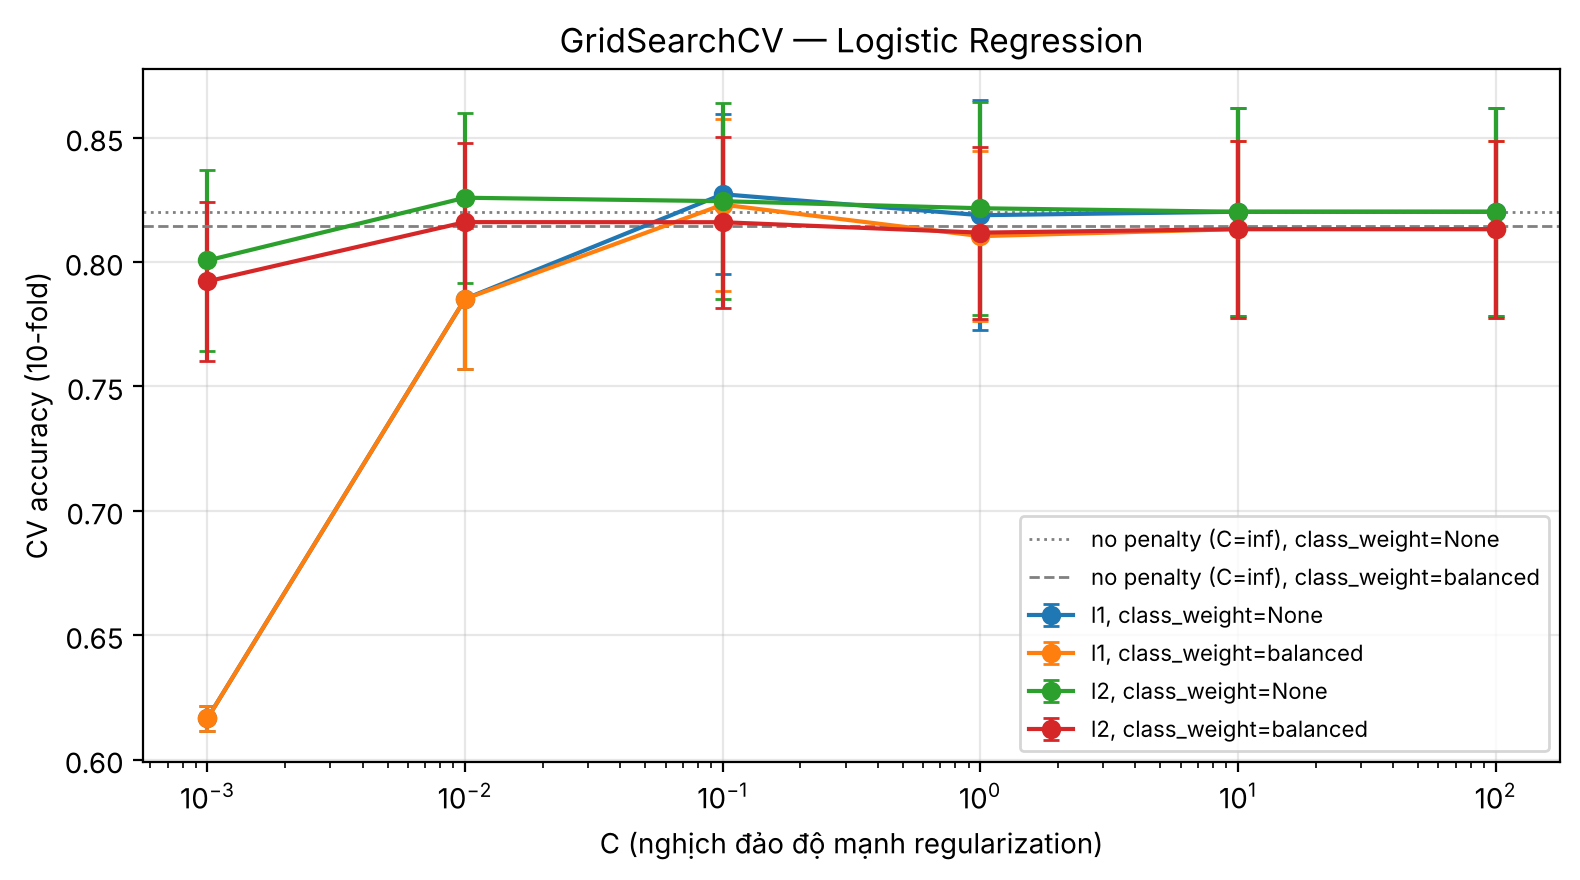

In [7]:
# Trực quan CV accuracy theo C cho từng penalty × class_weight
fig, ax = plt.subplots(figsize=(8, 4.5))
reg = cv_results[cv_results['penalty'] != 'none']
for (pen, cw), g in reg.groupby(['penalty', 'param_model__class_weight']):
    g = g.sort_values('param_model__C')
    ax.errorbar(g['param_model__C'].astype(float), g['mean_test_score'], yerr=g['std_test_score'],
                marker='o', capsize=3, label=f'{pen}, class_weight={cw}')
for (_, r), ls in zip(cv_results[cv_results['penalty'] == 'none'].iterrows(), [':', '--']):
    ax.axhline(r['mean_test_score'], ls=ls, color='gray', lw=1,
               label=f"no penalty (C=inf), class_weight={r['param_model__class_weight']}")
ax.set_xscale('log'); ax.set_xlabel('C (nghịch đảo độ mạnh regularization)'); ax.set_ylabel('CV accuracy (10-fold)')
ax.set_title('GridSearchCV — Logistic Regression'); ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG_DIR / '01_grid_search_cv_accuracy.png', dpi=150); plt.show()

## 6. Best estimator trên hold-out và so sánh với baseline

In [8]:
best_model = grid.best_estimator_
print('n_iter_ của best model:', best_model.named_steps['model'].n_iter_)
best_val, best_pred, best_score = evaluate(best_model, X_valid, y_valid, 'Tuned — validation')

comparison = pd.DataFrame({
    'baseline': {'cv_mean': baseline_cv.mean(), 'cv_std': baseline_cv.std(), **baseline_val},
    'tuned': {'cv_mean': grid.best_score_, 'cv_std': grid.cv_results_['std_test_score'][grid.best_index_], **best_val},
})
comparison['delta'] = comparison['tuned'] - comparison['baseline']
comparison.round(4)

n_iter_ của best model: [17]
=== Tuned — validation ===
accuracy     0.8380
precision    0.8125
recall       0.7536
f1           0.7820
roc_auc      0.8725
              precision    recall  f1-score   support

    Died (0)     0.8522    0.8909    0.8711       110
Survived (1)     0.8125    0.7536    0.7820        69

    accuracy                         0.8380       179
   macro avg     0.8323    0.8223    0.8265       179
weighted avg     0.8369    0.8380    0.8367       179

Confusion matrix [[TN, FP], [FN, TP]]:
 [[98 12]
 [17 52]]


,baseline,tuned,delta
cv_mean,0.8216,0.8272,0.0056
cv_std,0.0442,0.0322,-0.0120
accuracy,0.8324,0.8380,0.0056
precision,0.8095,0.8125,0.0030
recall,0.7391,0.7536,0.0145
f1,0.7727,0.7820,0.0092
roc_auc,0.8681,0.8725,0.0043


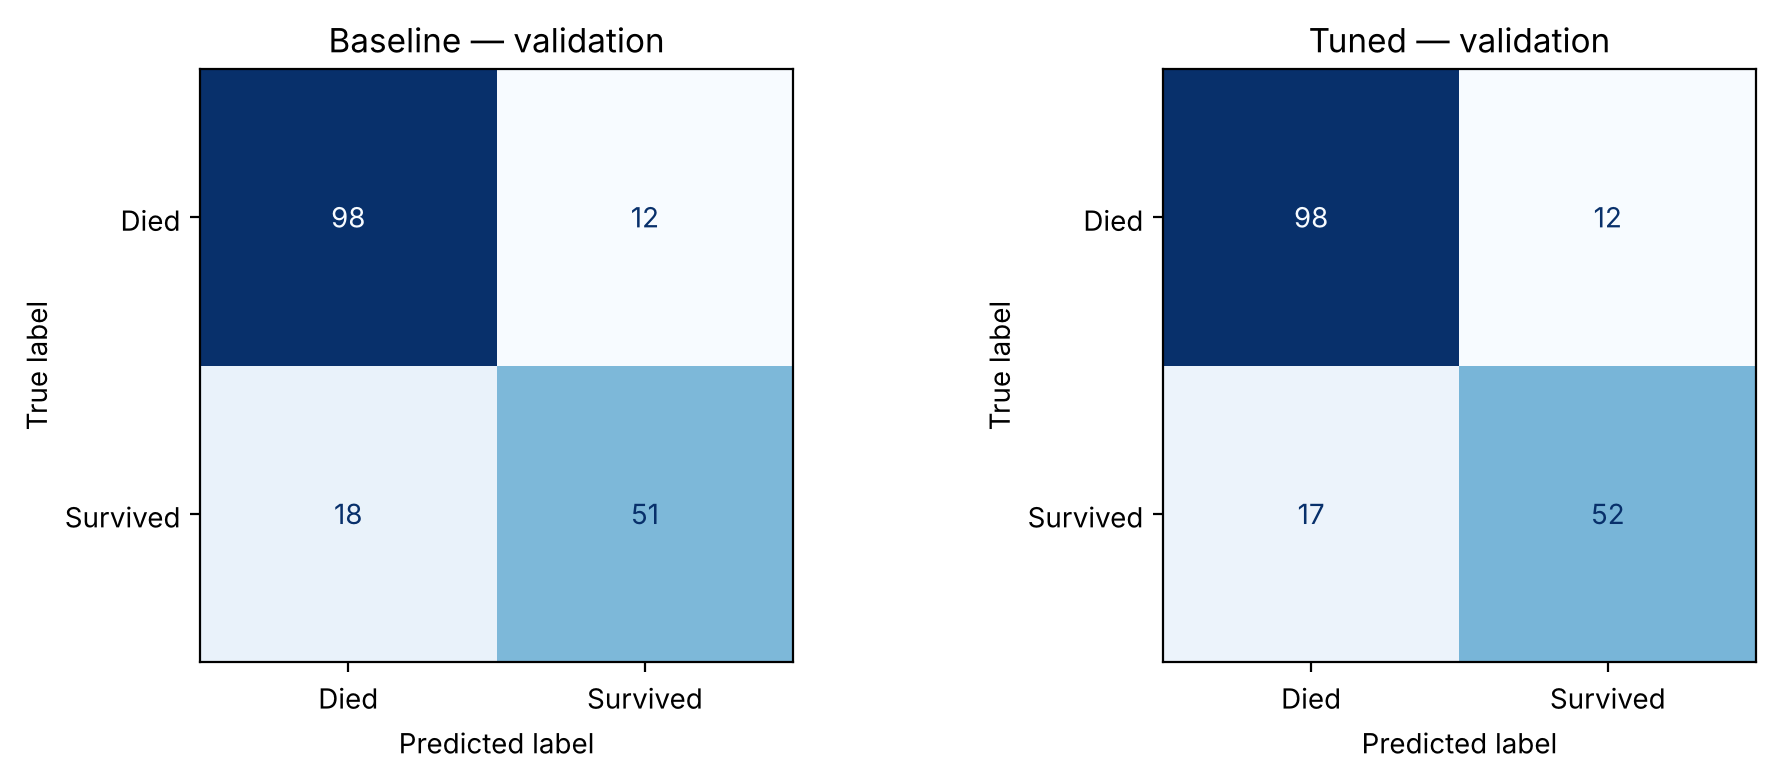

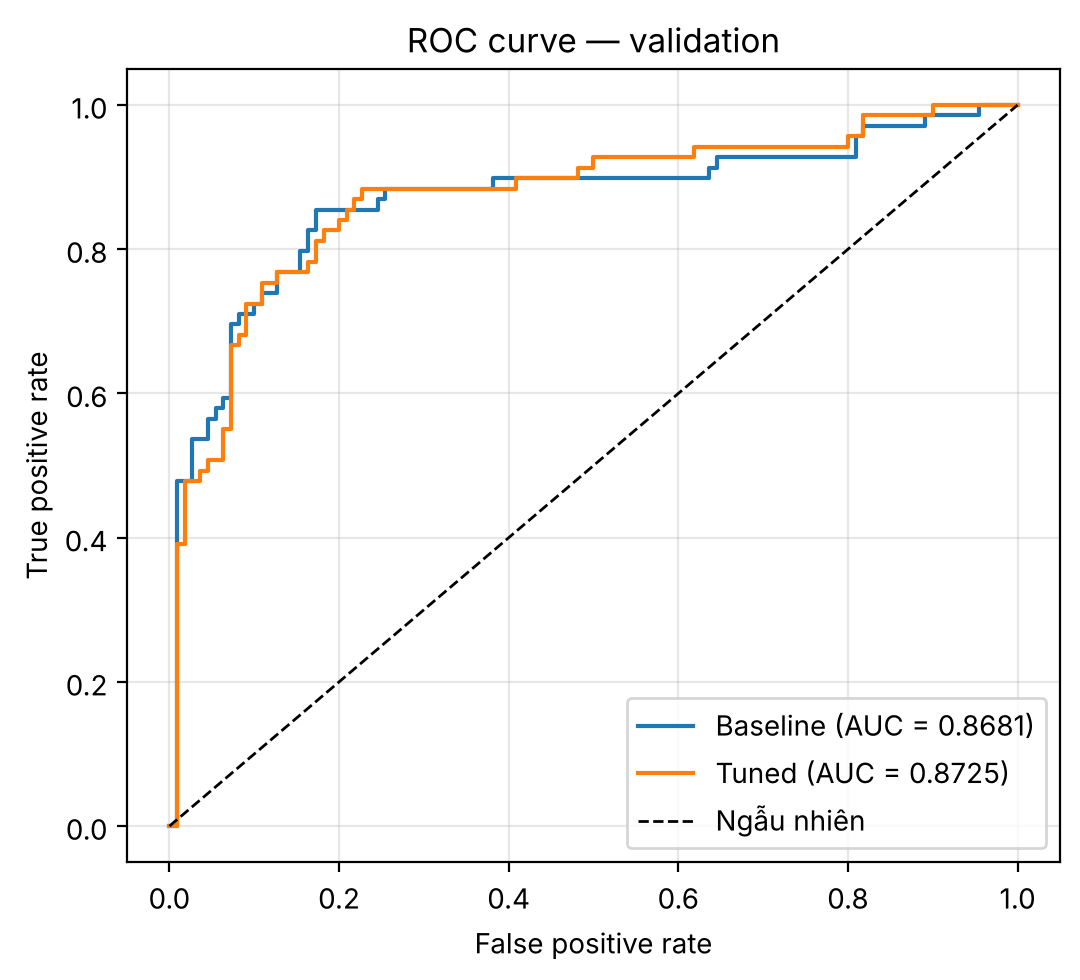

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], base_pred, 'Baseline'), (axes[1], best_pred, 'Tuned')]:
    ConfusionMatrixDisplay(confusion_matrix(y_valid, pred), display_labels=['Died', 'Survived']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{title} — validation')
fig.tight_layout(); fig.savefig(FIG_DIR / '02_confusion_matrix.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
for score, label in [(base_score, 'Baseline'), (best_score, 'Tuned')]:
    fpr, tpr, _ = roc_curve(y_valid, score)
    ax.plot(fpr, tpr, label=f'{label} (AUC = {roc_auc_score(y_valid, score):.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Ngẫu nhiên')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curve — validation')
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG_DIR / '03_roc_curve.png', dpi=150); plt.show()

## 7. Learning curve — phân tích bias/variance

Tính trên `X_train` với cùng `StratifiedKFold` (validation hold-out không tham gia).

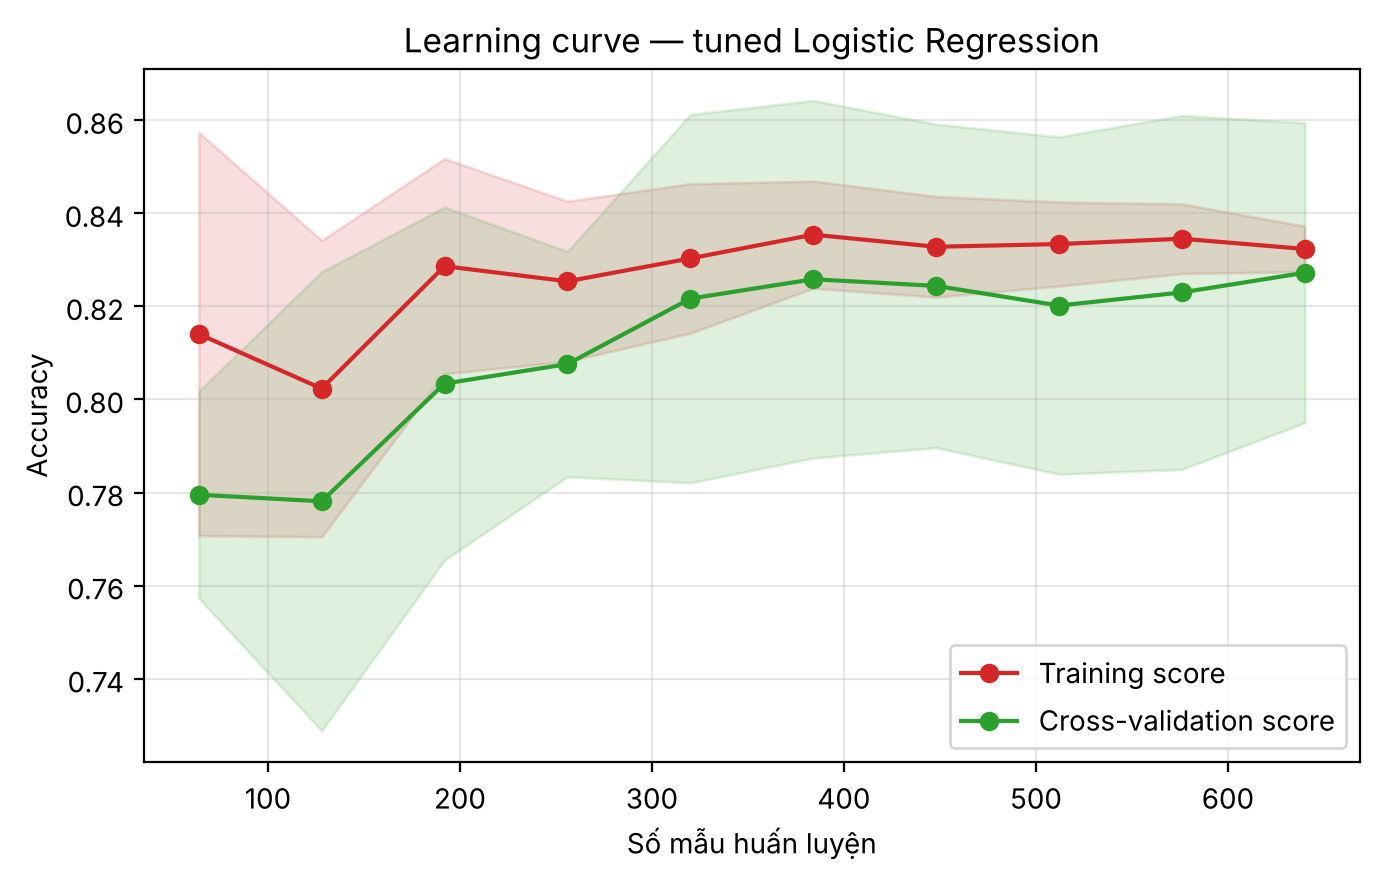

,train_size,train_mean,train_std,cv_mean,cv_std,gap
0,64,0.8141,0.0433,0.7795,0.0222,0.0345
1,128,0.8023,0.0318,0.7781,0.0493,0.0242
2,192,0.8286,0.0231,0.8034,0.0379,0.0252
3,256,0.8254,0.0172,0.8076,0.0242,0.0178
4,320,0.8303,0.0161,0.8217,0.0396,0.0086
5,384,0.8354,0.0115,0.8258,0.0384,0.0096
6,448,0.8328,0.0108,0.8244,0.0348,0.0084
7,512,0.8334,0.0090,0.8202,0.0362,0.0132
8,576,0.8345,0.0075,0.8230,0.0380,0.0115
9,640,0.8323,0.0049,0.8272,0.0322,0.0051


In [10]:
sizes, tr_scores, cv_scores = learning_curve(best_model, X_train, y_train, cv=cv, scoring='accuracy',
                                             train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, shuffle=True,
                                             random_state=RANDOM_STATE)
lc = pd.DataFrame({'train_size': sizes, 'train_mean': tr_scores.mean(1), 'train_std': tr_scores.std(1),
                   'cv_mean': cv_scores.mean(1), 'cv_std': cv_scores.std(1)})
lc['gap'] = lc['train_mean'] - lc['cv_mean']
fig, ax = plt.subplots(figsize=(7, 4.5))
for col, label, c in [('train', 'Training score', 'tab:red'), ('cv', 'Cross-validation score', 'tab:green')]:
    ax.plot(lc['train_size'], lc[f'{col}_mean'], 'o-', color=c, label=label)
    ax.fill_between(lc['train_size'], lc[f'{col}_mean'] - lc[f'{col}_std'], lc[f'{col}_mean'] + lc[f'{col}_std'], alpha=.15, color=c)
ax.set_xlabel('Số mẫu huấn luyện'); ax.set_ylabel('Accuracy'); ax.set_title('Learning curve — tuned Logistic Regression')
ax.legend(loc='lower right'); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG_DIR / '04_learning_curve.png', dpi=150); plt.show()
lc.round(4)

## 8. Hệ số của best model

Vì feature đã được chuẩn hóa bởi `StandardScaler`, mỗi hệ số là thay đổi log-odds sống sót khi feature tăng **1 độ lệch chuẩn** — nhờ đó so sánh được độ lớn giữa các feature. Lưu ý: nhiều feature tương quan mạnh (ví dụ `Sex`–`Title_*`, `Age`–`AgeBand_*`, `FamilySize`–`FamilyCategory_*`, one-hot đầy đủ) nên hệ số riêng lẻ có thể bị chia sẻ/triệt tiêu; đây là quan hệ dự báo, không phải nhân quả.

Intercept: -0.5395 | số hệ số = 0: 14


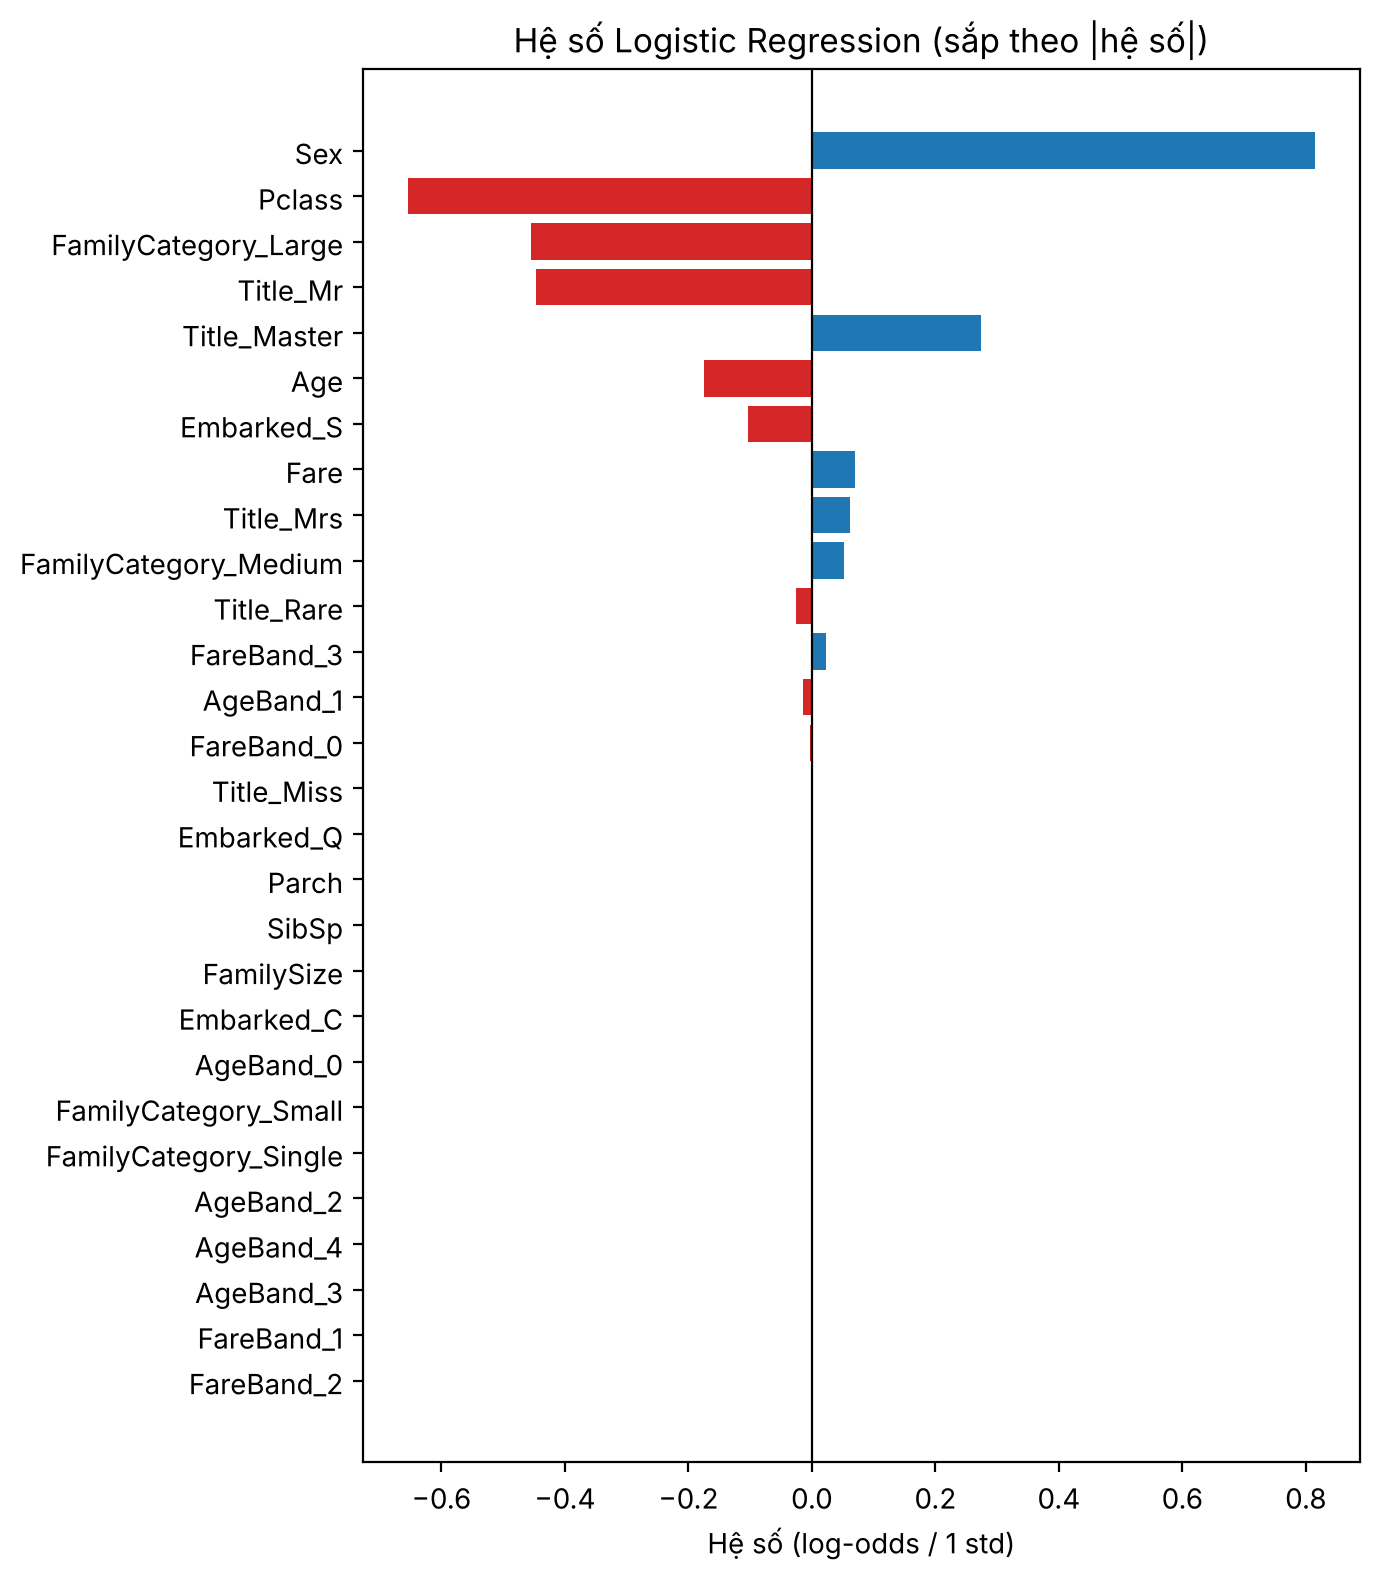

,feature,coefficient,odds_ratio_per_std,abs_coef
0,Sex,0.8143,2.2575,0.8143
1,Pclass,-0.6542,0.5199,0.6542
2,FamilyCategory_Large,-0.4556,0.6341,0.4556
3,Title_Mr,-0.4475,0.6393,0.4475
4,Title_Master,0.2731,1.3140,0.2731
5,Age,-0.1750,0.8394,0.1750
6,Embarked_S,-0.1042,0.9011,0.1042
7,Fare,0.0701,1.0727,0.0701
8,Title_Mrs,0.0609,1.0628,0.0609
9,FamilyCategory_Medium,0.0518,1.0531,0.0518


In [11]:
lr = best_model.named_steps['model']
coef = pd.DataFrame({'feature': FEATURES, 'coefficient': lr.coef_[0]})
coef['odds_ratio_per_std'] = np.exp(coef['coefficient'])
coef['abs_coef'] = coef['coefficient'].abs()
coef = coef.sort_values('abs_coef', ascending=False).reset_index(drop=True)
print('Intercept:', round(float(lr.intercept_[0]), 4), '| số hệ số = 0:', int((coef['coefficient'] == 0).sum()))

plot_df = coef.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(plot_df['feature'], plot_df['coefficient'], color=np.where(plot_df['coefficient'] > 0, 'tab:blue', 'tab:red'))
ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('Hệ số (log-odds / 1 std)'); ax.set_title('Hệ số Logistic Regression (sắp theo |hệ số|)')
fig.tight_layout(); fig.savefig(FIG_DIR / '05_coefficients.png', dpi=150); plt.show()
coef.round(4)

## 9. Refit trên toàn bộ dữ liệu có nhãn và dự đoán test

In [12]:
from sklearn.base import clone
final_model = clone(best_model)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always', ConvergenceWarning)
    final_model.fit(X_full, y_full)
print('ConvergenceWarning khi refit:', sum(issubclass(x.category, ConvergenceWarning) for x in w),
      '| n_iter_ =', final_model.named_steps['model'].n_iter_)
test_pred = final_model.predict(X_test).astype(int)
test_score = final_model.predict_proba(X_test)[:, 1]
print('Tỷ lệ dự đoán Survived=1 trên test:', round(test_pred.mean(), 4))

ConvergenceWarning khi refit: 0 | n_iter_ = [23]
Tỷ lệ dự đoán Survived=1 trên test: 0.3947


## 10. Xuất artifacts

In [13]:
joblib.dump(final_model, OUT_DIR / 'best_model.joblib')

best_params = {k.replace('model__', ''): (None if v is None else ('inf' if isinstance(v, float) and np.isinf(v) else v))
               for k, v in grid.best_params_.items()}
best_row = cv_results.loc[grid.best_index_]
metrics = {
    'model_name': 'Logistic Regression',
    'random_state': RANDOM_STATE,
    'cv_folds': cv.get_n_splits(),
    'baseline_cv_mean': float(baseline_cv.mean()),
    'baseline_cv_std': float(baseline_cv.std()),
    'best_cv_score': float(grid.best_score_),
    'best_cv_std': float(best_row['std_test_score']),
    'best_params': best_params,
    'best_penalty': best_row['penalty'],
    'validation_accuracy': float(best_val['accuracy']),
    'validation_precision': float(best_val['precision']),
    'validation_recall': float(best_val['recall']),
    'validation_f1': float(best_val['f1']),
    'validation_roc_auc': float(best_val['roc_auc']),
    'validation_confusion_matrix': confusion_matrix(y_valid, best_pred).tolist(),
    'baseline_validation': {k: float(v) for k, v in baseline_val.items()},
    'tuning_time_seconds': round(tuning_time, 2),
    'n_grid_configs': int(n_cfg),
    'score_definition': 'predict_proba[:, 1] = P(Survived=1)',
    'final_model_fit_on': 'X_full, y_full',
    'sklearn_version': sklearn.__version__,
    'notes': "sklearn 1.9 deprecates 'penalty': L2 = l1_ratio 0, L1 = l1_ratio 1, no penalty = C=inf (lbfgs).",
}
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding='utf-8')

cv_results.to_csv(OUT_DIR / 'cv_results.csv', index=False)
pd.DataFrame({'row_id': np.arange(len(X_valid)), 'y_true': y_valid.to_numpy(), 'y_pred': best_pred.astype(int),
              'y_score': best_score}).to_csv(OUT_DIR / 'validation_predictions.csv', index=False)
pd.DataFrame({'PassengerId': test_passenger_id, 'Survived': test_pred, 'score': test_score}).to_csv(OUT_DIR / 'test_predictions.csv', index=False)
pd.DataFrame({'PassengerId': test_passenger_id, 'Survived': test_pred}).to_csv(OUT_DIR / 'submission.csv', index=False)

# Kiểm tra lại đầu ra
sub = pd.read_csv(OUT_DIR / 'submission.csv')
assert sub.columns.tolist() == ['PassengerId', 'Survived'] and len(sub) == len(X_test) and set(sub['Survived']) <= {0, 1}
vp = pd.read_csv(OUT_DIR / 'validation_predictions.csv')
assert vp.columns.tolist() == ['row_id', 'y_true', 'y_pred', 'y_score'] and (vp['y_true'].to_numpy() == y_valid.to_numpy()).all()
assert pd.read_csv(OUT_DIR / 'test_predictions.csv').columns.tolist() == ['PassengerId', 'Survived', 'score']
reloaded = joblib.load(OUT_DIR / 'best_model.joblib')
assert (reloaded.predict(X_test) == test_pred).all()
for f in sorted(OUT_DIR.iterdir()): print(f.name, f.stat().st_size, 'bytes')
for f in sorted(FIG_DIR.iterdir()): print('figure:', f.name)

best_model.joblib 2845 bytes
cv_results.csv 17740 bytes
metrics.json 1185 bytes
submission.csv 2839 bytes
test_predictions.csv 10951 bytes
validation_predictions.csv 4808 bytes
figure: 01_grid_search_cv_accuracy.png
figure: 02_confusion_matrix.png
figure: 03_roc_curve.png
figure: 04_learning_curve.png
figure: 05_coefficients.png


## 11. Kết luận

**Kết quả chính** (số liệu lấy từ các cell phía trên; với `random_state=42` chạy lại cho cùng kết quả):

| | CV accuracy (10-fold, train) | Validation accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Baseline (L2, C=1) | 0.8216 ± 0.0442 | 0.8324 | 0.8095 | 0.7391 | 0.7727 | 0.8681 |
| Tuned (L1, C=0.1, `liblinear`, class_weight=None) | 0.8272 ± 0.0322 | 0.8380 | 0.8125 | 0.7536 | 0.7820 | 0.8725 |

- **Tuning:** 26 cấu hình × 10 fold, ~2 giây, không có ConvergenceWarning (`max_iter=5000` thừa đủ; số vòng lặp thực tế < 40). Mức cải thiện nhỏ (+0.006 CV accuracy, +1 dự đoán đúng trên validation) và nằm trong một độ lệch chuẩn CV, nên baseline và tuned gần như tương đương. Lợi ích rõ nhất của tuned model là **độ ổn định** (std giảm 0.044 → 0.032) và **mô hình gọn hơn** (L1 đưa 14/28 hệ số về 0).
- **class_weight='balanced'** cho CV accuracy thấp hơn `None` ở cùng C (cấu hình balanced tốt nhất: 0.8230); với tỷ lệ lớp ~38/62 không quá lệch và metric chính là accuracy, không cân bằng lại là hợp lý. Regularization quá mạnh (C=0.001, đặc biệt với L1) gây underfit rõ rệt.
- **Bias/variance:** learning curve cho thấy train và CV accuracy hội tụ quanh 0.83, khoảng cách cuối chỉ ~0.005 → **không overfit, mô hình bị giới hạn bởi bias** (ranh giới tuyến tính). Thêm dữ liệu cùng loại khó cải thiện nhiều; cần mô hình phi tuyến hoặc feature tương tác để vượt mức ~0.83.
- **Hệ số:** `Sex` (nữ, +) và `Pclass` (hạng thấp, −) mạnh nhất; tiếp theo là `FamilyCategory_Large` (−), `Title_Mr` (−), `Title_Master` (+) và `Age` (−). Phù hợp với EDA chung (“women and children first”, ưu thế hạng vé). Do feature tương quan mạnh (Sex↔Title, Age↔AgeBand, FamilySize↔FamilyCategory), L1 chỉ giữ một đại diện của nhóm, nên hệ số = 0 không có nghĩa feature vô dụng.

**Hạn chế:** validation chỉ 179 dòng (1 dự đoán ≈ 0.56% accuracy) nên chênh lệch giữa các cấu hình đều nhỏ hơn nhiễu; hệ số mang tính dự báo, không phải nhân quả; mô hình tuyến tính không học được tương tác như `Sex × Pclass`.

**Đề xuất cải tiến:** thêm feature tương tác (`Sex×Pclass`, `Title×Pclass`) trong phần chung nếu nhóm thống nhất; thử `elasticnet` (`l1_ratio` trung gian, solver `saga`); dùng repeated CV để so sánh cấu hình ổn định hơn; tối ưu ngưỡng phân loại nếu nhóm ưu tiên recall.